## Dataset Overview: Building Energy Consumption
**MCC Machine Learning Track — Week 3: Regression**

This dataset contains **1,100 records** (merged from the 1,000-row training split and 100-row testing split) designed for regression modeling. The goal is to predict a building's total energy consumption based on its structural characteristics, occupancy, and environmental conditions.

### Features Description
| Feature | Data Type | Role | Description |
| :--- | :--- | :--- | :--- |
| **`Building Type`** | Categorical | Feature | Category of the building (`Residential`, `Commercial`, `Industrial`) |
| **`Square Footage`** | Numerical | Feature | Total floor area of the building (sq. ft.) |
| **`Number of Occupants`** | Numerical | Feature | Number of people inside the building |
| **`Appliances Used`** | Numerical | Feature | Count of active appliances in use |
| **`Average Temperature`** | Numerical | Feature | Average ambient temperature (°C) |
| **`Day of Week`** | Categorical | Feature | Whether the record was logged on a `Weekday` or `Weekend` |
| **`Energy Consumption`** | Numerical | **Target ($y$)** | Total energy consumed by the building |

**Source:** [Kaggle — Energy Consumption Dataset](https://www.kaggle.com/datasets/govindaramsriram/energy-consumption-dataset-linear-regression)

In [29]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler, StandardScaler
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [30]:
df = pd.read_csv(r"train_energy_data.csv")
df.sample(5)

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week,Energy Consumption
99,Commercial,40166,70,35,13.05,Weekend,5343.05
11,Commercial,47265,4,44,25.38,Weekday,5206.34
503,Residential,32390,84,15,27.44,Weekday,4172.29
543,Commercial,1322,81,2,15.38,Weekend,2839.18
888,Residential,8304,98,46,18.82,Weekday,3771.12


# 1. Data Understanding

In [31]:
df.columns

Index(['Building Type', 'Square Footage', 'Number of Occupants',
       'Appliances Used', 'Average Temperature', 'Day of Week',
       'Energy Consumption'],
      dtype='str')

In [32]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Building Type        1000 non-null   str    
 1   Square Footage       1000 non-null   int64  
 2   Number of Occupants  1000 non-null   int64  
 3   Appliances Used      1000 non-null   int64  
 4   Average Temperature  1000 non-null   float64
 5   Day of Week          1000 non-null   str    
 6   Energy Consumption   1000 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 54.8 KB


In [33]:
df.isnull().sum()

Building Type          0
Square Footage         0
Number of Occupants    0
Appliances Used        0
Average Temperature    0
Day of Week            0
Energy Consumption     0
dtype: int64

In [34]:
df.duplicated().sum()

np.int64(0)

In [35]:
# Numerical Static Description 
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Square Footage,1000.0,25462.38800,14294.554000,560.00,13169.7500,25477.000,37446.25,49997.00
Number of Occupants,1000.0,48.37200,29.061972,1.00,22.0000,47.000,73.25,99.00
Appliances Used,1000.0,25.60600,14.105166,1.00,13.0000,26.000,38.00,49.00
Average Temperature,1000.0,22.61139,7.139943,10.05,16.4750,22.815,28.85,34.99
Energy Consumption,1000.0,4166.25257,933.313064,1683.95,3509.4825,4175.730,4863.85,6530.60


In [36]:
df.select_dtypes('str').describe().T

,count,unique,top,freq
Building Type,1000,3,Residential,347
Day of Week,1000,2,Weekday,507


In [37]:
cat_cols = df.select_dtypes('str').columns
for col in cat_cols:
    display(df[col].value_counts())

Building Type
Residential    347
Commercial     336
Industrial     317
Name: count, dtype: int64

Day of Week
Weekday    507
Weekend    493
Name: count, dtype: int64

# 2. EDA and Feature Eng

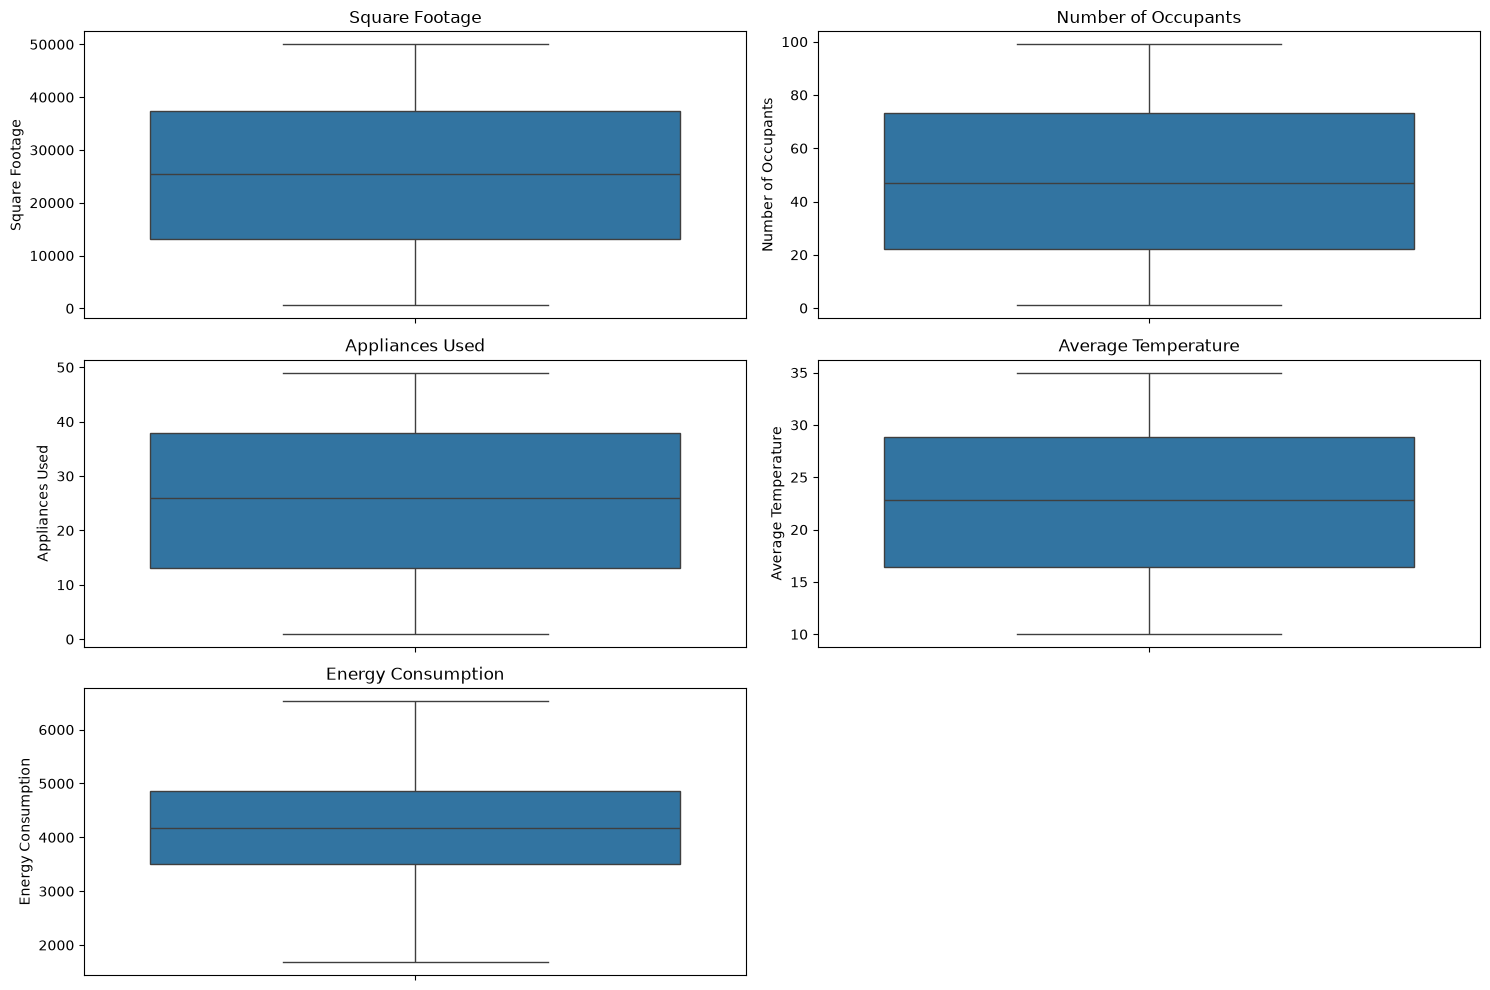

In [38]:
# Visualize the box plot for outliers
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.boxplot(data=df, y=col)
    plt.title(col)

plt.tight_layout()
plt.show()

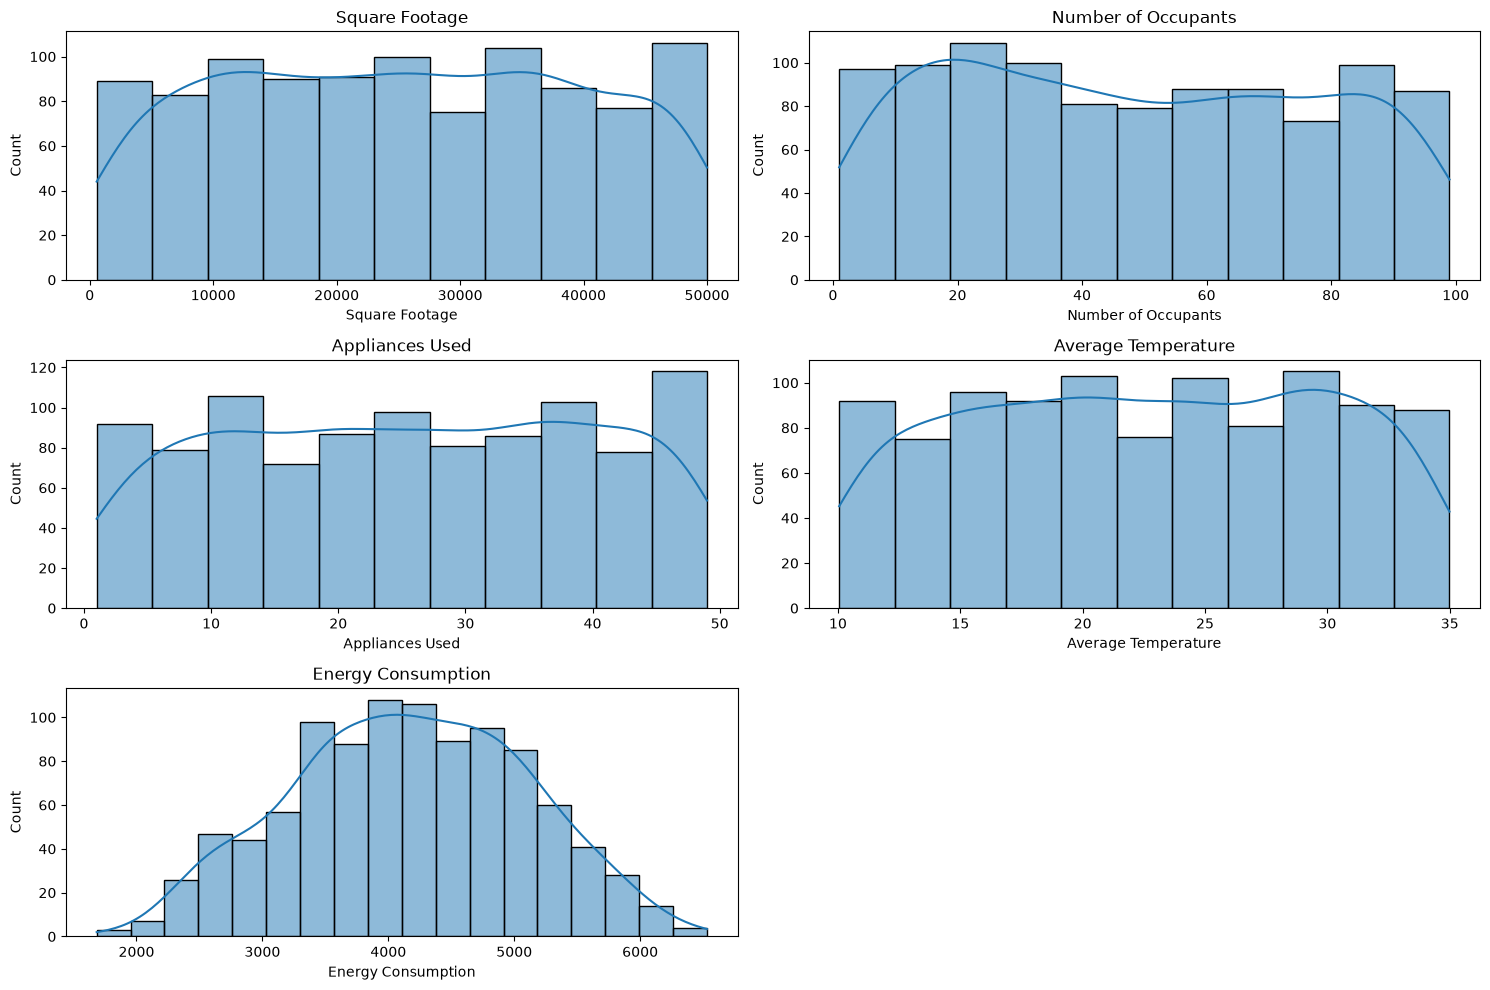

In [39]:
# Visualize the distribution of the data
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.histplot(data=df, x=col, kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

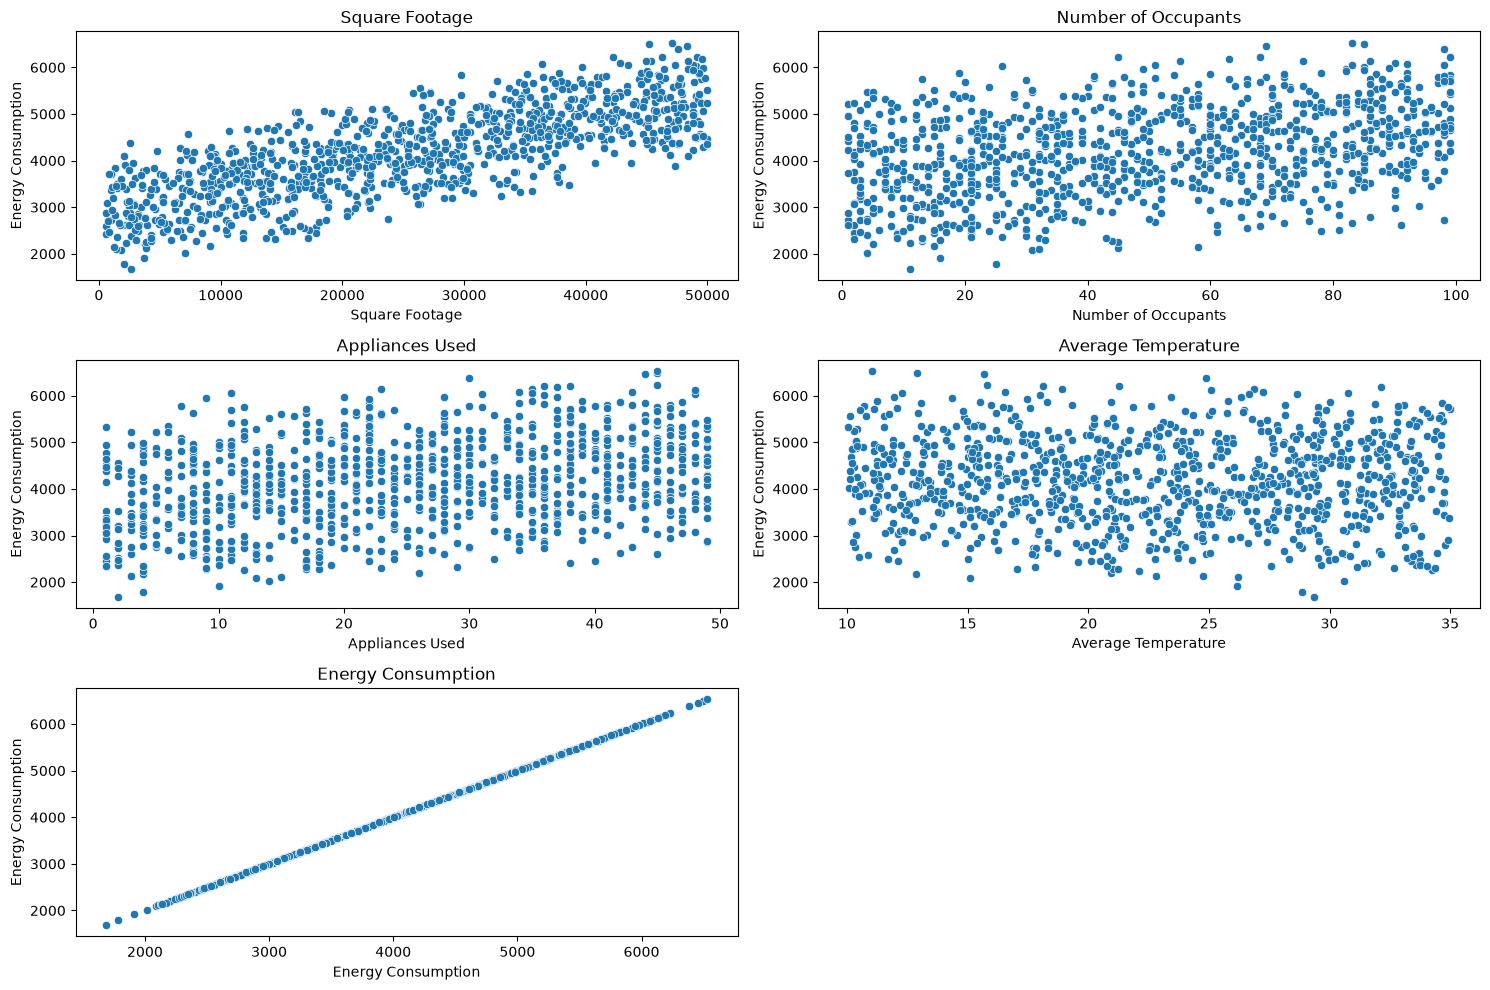

In [40]:
# Visualize 
num_cols = df.select_dtypes('number').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.scatterplot(data=df, x=df[col], y=df['Energy Consumption'])
    plt.title(col)

plt.tight_layout()
plt.show()

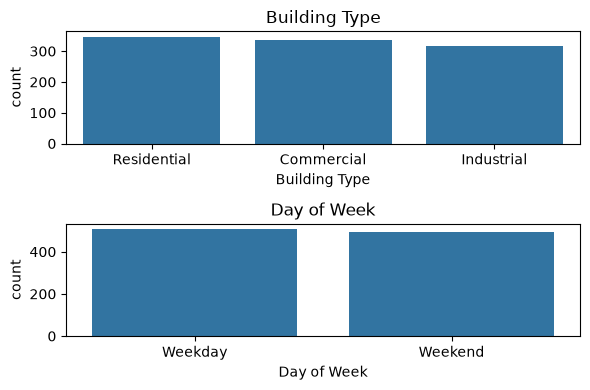

In [41]:

num_cols = df.select_dtypes('str').columns

plt.figure(figsize=(6, 4))

for index, col in enumerate(num_cols, 1):
    plt.subplot(2,1, index)
    sns.countplot(data=df, x=col)
    plt.title(col)

plt.tight_layout()
plt.show()

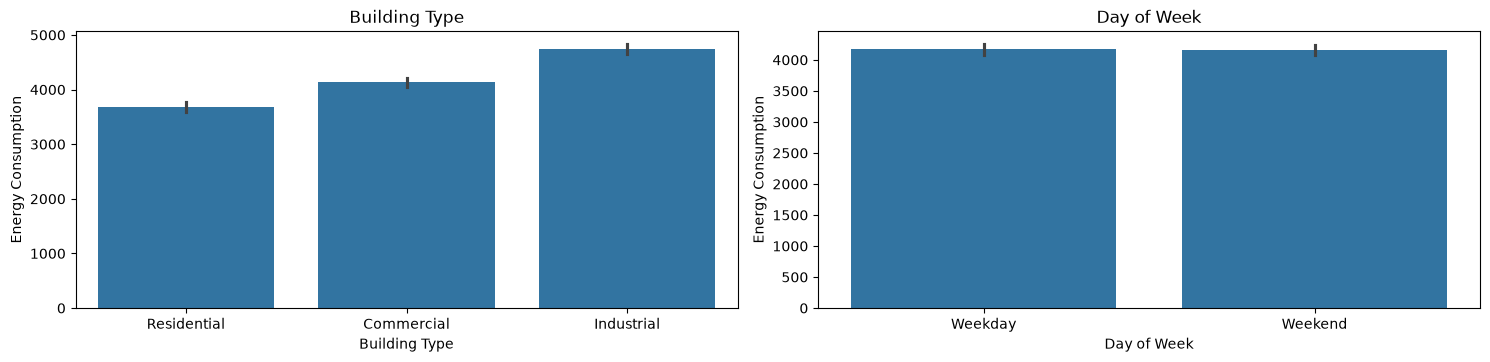

In [42]:
# Visualize the box plot for outliers
num_cols = df.select_dtypes('str').columns

plt.figure(figsize=(15, 10))

for index, col in enumerate(num_cols, 1):
    plt.subplot(3,2, index)
    sns.barplot(data=df, x=col, y='Energy Consumption')
    plt.title(col)

plt.tight_layout()
plt.show()

<Axes: >

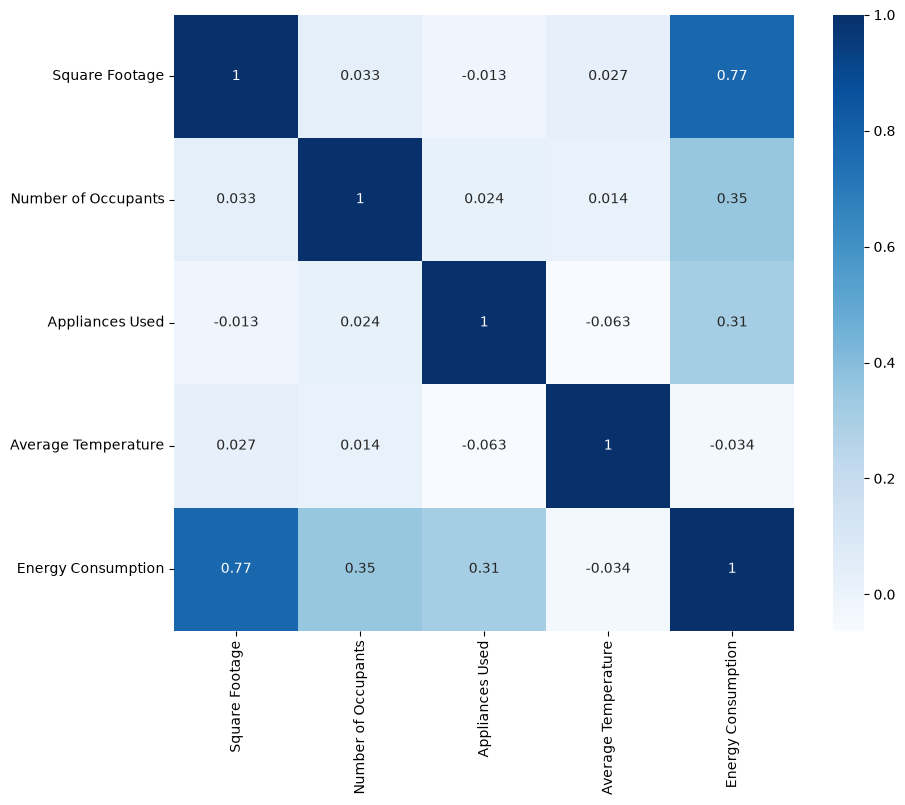

In [43]:
corr = df.select_dtypes('number').corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='Blues')

# 3. Preprocessing

In [44]:
# Split The data
X, y = df.drop(columns= ['Energy Consumption']), df['Energy Consumption']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [45]:
display(X_train)
display(y_train)

,Building Type,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Day of Week
29,Residential,27072,12,30,32.89,Weekend
535,Commercial,9874,5,19,20.65,Weekday
695,Industrial,22427,8,13,26.21,Weekday
557,Residential,30129,29,33,23.73,Weekend
836,Commercial,16350,14,38,18.39,Weekday
...,...,...,...,...,...,...
106,Commercial,6776,84,29,17.20,Weekday
270,Industrial,12164,82,41,23.04,Weekday
860,Commercial,27338,37,49,33.14,Weekday
435,Industrial,27089,69,25,29.33,Weekday


29     3409.14
535    2870.44
695    3880.32
557    3837.78
836    3675.54
        ...   
106    3722.80
270    4683.00
860    4601.21
435    4947.78
102    2648.85
Name: Energy Consumption, Length: 800, dtype: float64

In [46]:
# Encoding and Scaling

cat_cols = df.select_dtypes('str').columns

encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

train_encoded = encoder.fit_transform(X_train[cat_cols])
test_encoded = encoder.transform(X_test[cat_cols])

cols_names = encoder.get_feature_names_out(cat_cols)

train_encoded = pd.DataFrame(train_encoded, columns=cols_names, index=X_train.index)
test_encoded = pd.DataFrame(test_encoded, columns=cols_names, index=X_test.index)

X_train = X_train.drop(columns=cat_cols)
X_test = X_test.drop(columns=cat_cols)

X_train = pd.concat([X_train, train_encoded], axis=1)
X_test = pd.concat([X_test, test_encoded], axis=1)

In [47]:
display(X_train.head(), '\n')
display(X_test.head())

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
29,27072,12,30,32.89,0.0,0.0,1.0,0.0,1.0
535,9874,5,19,20.65,1.0,0.0,0.0,1.0,0.0
695,22427,8,13,26.21,0.0,1.0,0.0,1.0,0.0
557,30129,29,33,23.73,0.0,0.0,1.0,0.0,1.0
836,16350,14,38,18.39,1.0,0.0,0.0,1.0,0.0


'\n'

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
521,40192,23,23,30.00,1.0,0.0,0.0,0.0,1.0
737,8406,25,36,19.48,0.0,0.0,1.0,1.0,0.0
740,47719,92,7,32.82,0.0,1.0,0.0,0.0,1.0
660,37435,26,35,21.64,1.0,0.0,0.0,1.0,0.0
411,11331,47,43,21.10,1.0,0.0,0.0,0.0,1.0


In [48]:
X_train.columns

Index(['Square Footage', 'Number of Occupants', 'Appliances Used',
       'Average Temperature', 'Building Type_Commercial',
       'Building Type_Industrial', 'Building Type_Residential',
       'Day of Week_Weekday', 'Day of Week_Weekend'],
      dtype='str')

In [49]:
# Scaling
scaler = MinMaxScaler()
columns = X_train.columns
cols_names = ['Square Footage', 'Number of Occupants', 'Appliances Used',
       'Average Temperature']

X_train[cols_names] = scaler.fit_transform(X_train[cols_names])
X_test[cols_names] = scaler.transform(X_test[cols_names])

In [50]:
display(pd.DataFrame(X_train, columns=columns))
display(pd.DataFrame(X_test, columns=columns))

,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
29,0.536452,0.112245,0.604167,0.917372,0.0,0.0,1.0,0.0,1.0
535,0.188462,0.040816,0.375000,0.424023,1.0,0.0,0.0,1.0,0.0
695,0.442464,0.071429,0.250000,0.648126,0.0,1.0,0.0,1.0,0.0
557,0.598308,0.285714,0.666667,0.548166,0.0,0.0,1.0,0.0,1.0
836,0.319500,0.132653,0.770833,0.332930,1.0,0.0,0.0,1.0,0.0
...,...,...,...,...,...,...,...,...,...
106,0.125776,0.846939,0.583333,0.284966,1.0,0.0,0.0,1.0,0.0
270,0.234799,0.826531,0.833333,0.520355,0.0,1.0,0.0,1.0,0.0
860,0.541834,0.367347,1.000000,0.927449,1.0,0.0,0.0,1.0,0.0
435,0.536796,0.693878,0.500000,0.773881,0.0,1.0,0.0,1.0,0.0


,Square Footage,Number of Occupants,Appliances Used,Average Temperature,Building Type_Commercial,Building Type_Industrial,Building Type_Residential,Day of Week_Weekday,Day of Week_Weekend
521,0.801926,0.224490,0.458333,0.800887,1.0,0.0,0.0,0.0,1.0
737,0.158758,0.244898,0.729167,0.376864,0.0,0.0,1.0,1.0,0.0
740,0.954230,0.928571,0.125000,0.914551,0.0,1.0,0.0,0.0,1.0
660,0.746140,0.255102,0.708333,0.463926,1.0,0.0,0.0,1.0,0.0
411,0.217944,0.469388,0.875000,0.442160,1.0,0.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
408,0.039052,0.918367,0.145833,0.600564,0.0,0.0,1.0,1.0,0.0
332,0.461949,0.500000,0.458333,0.550988,0.0,0.0,1.0,0.0,1.0
208,0.061371,0.887755,0.833333,0.489319,1.0,0.0,0.0,0.0,1.0
613,0.813966,0.346939,0.062500,0.155582,0.0,0.0,1.0,1.0,0.0


# Modeling

In [51]:
# Linear Regression Model
lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](9,)","[2471.05, 980. , 960. ,...,-500. , 25. , -25. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](9,)","['Square Footage','Number of Occupants','Appliances Used',..., 'Building Type_Residential','Day of Week_Weekday','Day of Week_Weekend']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2032
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,9
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)


In [52]:
y_train_pred = lr.predict(X_train)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_train_pred, y_train)}")
print(f"MAE: {mean_absolute_error(y_train_pred, y_train)}")
print(f"R2 Score: {r2_score(y_train_pred, y_train)}")

===================Loss==========================
MSE: 0.0001861993111377946
MAE: 0.011691385892450796
R2 Score: 0.9999999997890103


In [53]:
# Test
y_pred = lr.predict(X_test)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_pred, y_test)}")
print(f"MAE: {mean_absolute_error(y_pred, y_test)}")
print(f"R2 Score: {r2_score(y_pred, y_test)}")

===================Loss==========================
MSE: 0.00018855085579345753
MAE: 0.011412201077562259
R2 Score: 0.9999999997684501


### Evaluation Metrics Summary
1. **Mean Squared Error (MSE):** Averages the squared differences between actual and predicted values (penalizes large errors heavily).
   $$MSE = \frac{1}{n} \sum_{i=1}^{n} (y_i - \hat{y}_i)^2$$

2. **Mean Absolute Error (MAE):** Averages the absolute differences in the same unit as the target variable.
   $$MAE = \frac{1}{n} \sum_{i=1}^{n} |y_i - \hat{y}_i|$$

3. **R-Squared ($R^2$ Score):** Measures the proportion of variance in the target explained by the features compared to simply guessing the mean $\bar{y}$ (closer to $1$ is better).
   $$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

In [54]:
# Train SGDRegressor

sgd_model = SGDRegressor(
        loss="squared_error",
        max_iter=3000,
        learning_rate="constant",
        eta0=0.01,                  # Learning Rate
        random_state=42,
    )

sgd_model.fit(X_train, y_train)

c:\Users\mazen\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:1620: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",3000
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"learning_rate learning_rate: str, default='invscaling'The learning rate schedule:- 'constant': `eta = eta0`- 'optimal': `eta = 1.0 / (alpha * (t + t0))` where t0 is chosen by a heuristic proposed by Leon Bottou.- 'invscaling': `eta = eta0 / pow(t, power_t)`- 'adaptive': eta = eta0, as long as the training keeps decreasing. Each time n_iter_no_change consecutive epochs fail to decrease the training loss by tol or fail to increase validation score by tol if early_stopping is True, the current learning rate is divided by 5.- 'pa1': passive-aggressive algorithm 1, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = min(eta0, loss/||x||**2)`.- 'pa2': passive-aggressive algorithm 2, see [1]_. Only with `loss='epsilon_insensitive'`. Update is `w += eta y x` with `eta = hinge_loss / (||x||**2 + 1/(2 eta0))`... versionadded:: 0.20 Added 'adaptive' option... versionadded:: 1.8 Added options 'pa1' and 'pa2'",'constant'
,"loss loss: str, default='squared_error'The loss function to be used. The possible values are 'squared_error','huber', 'epsilon_insensitive', or 'squared_epsilon_insensitive'The 'squared_error' refers to the ordinary least squares fit.'huber' modifies 'squared_error' to focus less on getting outlierscorrect by switching from squared to linear loss past a distance ofepsilon. 'epsilon_insensitive' ignores errors less than epsilon and islinear past that; this is the loss function used in SVR.'squared_epsilon_insensitive' is the same but becomes squared loss pasta tolerance of epsilon.More details about the losses formulas can be found in the:ref:`User Guide <sgd_mathematical_formulation>`.",'squared_error'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0


In [55]:
y_train_pred = sgd_model.predict(X_train)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_train_pred, y_train)}")
print(f"MAE: {mean_absolute_error(y_train_pred, y_train)}")
print(f"R2 Score: {r2_score(y_train_pred, y_train)}")

===================Loss==========================
MSE: 0.8517123446658715
MAE: 0.7796749241056787
R2 Score: 0.9999990331148086


In [56]:
y_pred = sgd_model.predict(X_test)

print("===================Loss==========================")
print(f"MSE: {mean_squared_error(y_pred, y_test)}")
print(f"MAE: {mean_absolute_error(y_pred, y_test)}")
print(f"R2 Score: {r2_score(y_pred, y_test)}")

===================Loss==========================
MSE: 0.8015929792305329
MAE: 0.750333091924183
R2 Score: 0.9999990137871313
